In [1]:
import os, sys, json, time
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score, precision_score
from src.data import load_split, make_dataset, CLASSES

train_df, val_df, test_df = load_split(PROJECT_ROOT)
y_val = val_df["label"].values

idx = np.arange(len(CLASSES))
w = compute_class_weight("balanced", classes=idx, y=train_df["label"].values)
class_weight_sqrt = {int(i): float(np.sqrt(x)) for i, x in zip(idx, w)}

model = keras.models.load_model(os.path.join(PROJECT_ROOT, "models", "mobilenetv2_head_sqrt.keras"))
print("Loaded:", model.name, "| weights:", {CLASSES[i]: round(x, 2) for i, x in class_weight_sqrt.items()})

Loaded: mobilenetv2_sqrtweights | weights: {'akiec': 2.09, 'bcc': 1.65, 'bkl': 1.14, 'df': 3.63, 'mel': 1.13, 'nv': 0.46, 'vasc': 3.18}


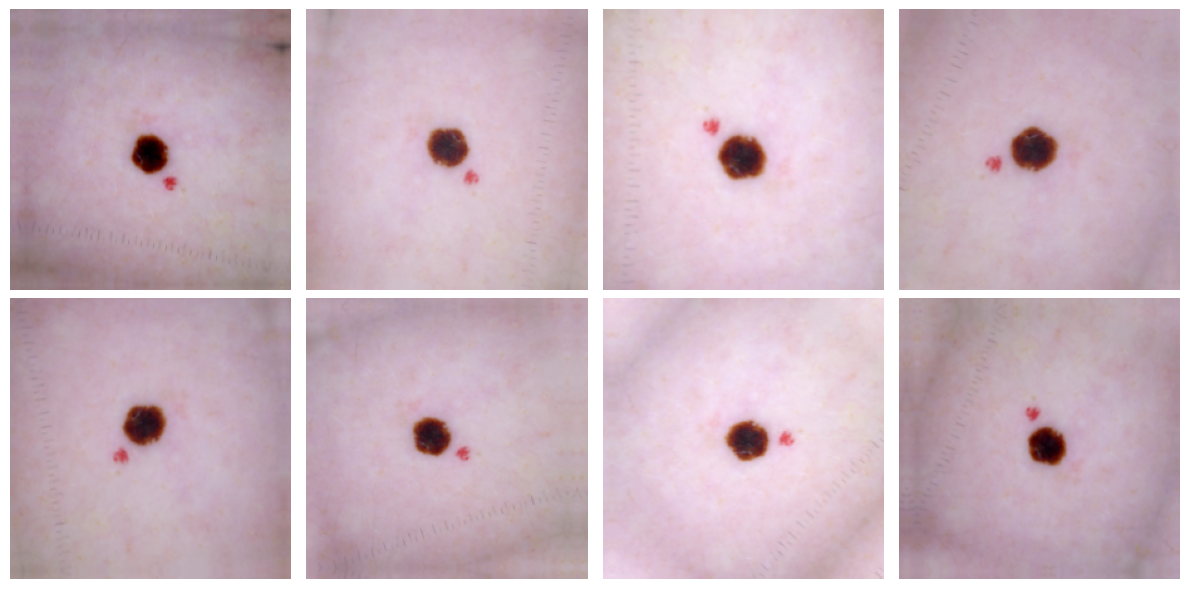

In [2]:
one = train_df[train_df["dx"] == "mel"].iloc[:1]
ds = make_dataset(one.loc[one.index.repeat(8)].reset_index(drop=True), batch_size=8, training=True, augment="v2")
imgs, _ = next(iter(ds))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, im in zip(axes.ravel(), imgs):
    ax.imshow(im.numpy().astype("uint8")); ax.axis("off")
plt.tight_layout(); plt.show()

In [3]:
base = next(l for l in model.layers if isinstance(l, keras.Model))
print("Base layers:", len(base.layers))
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
print("Trainable params now:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

train_ds = make_dataset(train_df, batch_size=32, training=True, augment="v2")
val_ds = make_dataset(val_df, batch_size=32, training=False)

MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "mobilenetv2_finetuned_sqrt_aug2.keras"),
                                    monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=15,
                 class_weight=class_weight_sqrt, callbacks=callbacks)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")
best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
print("Best epoch:", best_epoch)

val_probs = model.predict(val_ds, verbose=0)
val_pred = val_probs.argmax(axis=1)
res = {"model": "mobilenetv2_finetuned_sqrt_aug2",
       "val_accuracy": float((val_pred == y_val).mean()),
       "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred)),
       "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
       "mel_recall": float(recall_score(y_val, val_pred, labels=[4], average=None)[0]),
       "mel_precision": float(precision_score(y_val, val_pred, labels=[4], average=None)[0]),
       "best_epoch": best_epoch}
with open(os.path.join(PROJECT_ROOT, "results", "finetuned_mobilenet_sqrt_aug2.json"), "w") as f:
    json.dump(res, f, indent=2)
print(json.dumps(res, indent=2))

Base layers: 154
Trainable params now: 1519687
Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 203s 898ms/step - accuracy: 0.7151 - loss: 0.7921 - val_accuracy: 0.6606 - val_loss: 0.8913 - learning_rate: 1.0000e-05
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 193s 876ms/step - accuracy: 0.7308 - loss: 0.7328 - val_accuracy: 0.6332 - val_loss: 0.9481 - learning_rate: 1.0000e-05
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 193s 877ms/step - accuracy: 0.7418 - loss: 0.7079 - val_accuracy: 0.6756 - val_loss: 0.8568 - learning_rate: 1.0000e-05
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 199s 900ms/step - accuracy: 0.7455 - loss: 0.6963 - val_accuracy: 0.6730 - val_loss: 0.8311 - learning_rate: 1.0000e-05
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 195s 882ms/step - accuracy: 0.7531 - loss: 0.6625 - val_accuracy: 0.6749 - val_loss: 0.8181 - learning_rate: 1.0000e-05
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 196s 888ms/step - accuracy: 0.7655 - loss: 0.6313 - val_accuracy: 0.6704 - val_loss: 0.8662 - learning_rate: 1.0000e-05
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 191s 865ms/

In [4]:
print(json.load(open(os.path.join(PROJECT_ROOT, "results", "finetuned_mobilenet_sqrt_aug2.json"))))

{'model': 'mobilenetv2_finetuned_sqrt_aug2', 'val_accuracy': 0.6932114882506527, 'val_balanced_accuracy': 0.5441403230924476, 'val_macro_f1': 0.5059326785797517, 'mel_recall': 0.5058823529411764, 'mel_precision': 0.39814814814814814, 'best_epoch': 7}
